# 04. Economics of the approval cut-off
Profit of the portfolio as a function of the approval rate, for the four models of stage 3.
Assumptions (decision 31): a repaid loan earns **margin = 10%** of its amount over its life,
a defaulted loan loses **LGD = 65%** of it; EAD = `AMT_CREDIT`. Break-even PD = 0.10 / 0.75 = 13.3%.
The model is an overlay on the current policy: clients are already approved, so *approve all* is the
baseline. The cut-off is chosen on **valid**; test is used once at the end (decision 30).
Amounts are in the currency of `AMT_CREDIT` (not specified in the dataset).

In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.economics import (break_even_pd, client_profit, optimal_cutoff,
                           portfolio_at_pd_cutoff, profit_curve)
from src.viz import INK_MUTED, INK_SECONDARY, SERIES, apply_style, save_figure

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MARGIN, LGD = 0.10, 0.65
BREAK_EVEN = break_even_pd(MARGIN, LGD)

apply_style()
pd.set_option("display.max_columns", 30, "display.width", 200)

valid = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "valid_predictions.parquet")
assert len(valid) == 61_502

MODELS = {
    "scorecard_with_ext": "Scorecard (logreg on WoE), with EXT_SOURCE",
    "scorecard_no_ext": "Scorecard (logreg on WoE), no EXT_SOURCE",
    "lightgbm_with_ext": "LightGBM, with EXT_SOURCE",
    "lightgbm_no_ext": "LightGBM, no EXT_SOURCE",
}
y, ead = valid["TARGET"], valid["AMT_CREDIT"]
print(f"Break-even PD: {BREAK_EVEN:.1%}")

Break-even PD: 13.3%


## 4.3 Profit curves and the optimal cut-off (valid)

In [10]:
# Baseline: the current policy approves everyone in this sample
baseline_profit = client_profit(y, ead, MARGIN, LGD).sum()
baseline = {"clients": len(valid), "bad_rate": y.mean(), "loan_volume": ead.sum(),
            "profit": baseline_profit, "profit_to_volume": baseline_profit / ead.sum()}
pd.Series(baseline).round(4)

clients             6.150200e+04
bad_rate            8.070000e-02
loan_volume         3.688701e+10
profit              1.590172e+09
profit_to_volume    4.310000e-02
dtype: float64

In [11]:
curves = {key: profit_curve(valid[f"pd_{key}"], y, ead, MARGIN, LGD, step=0.005) for key in MODELS}

rows = []
for key in MODELS:
    best = optimal_cutoff(curves[key])
    rule = portfolio_at_pd_cutoff(valid[f"pd_{key}"], y, ead, BREAK_EVEN, MARGIN, LGD)
    rows.append({
        "model": key,
        # Empirical optimum: the approval rate with the highest realized profit on valid
        "opt_approval_rate": best["approval_rate"],
        "opt_pd_cutoff": best["pd_cutoff"],
        "opt_bad_rate": best["bad_rate"],
        "opt_profit": best["profit"],
        # Theoretical rule: approve if PD < break-even PD (relies on calibrated PD)
        "rule_approval_rate": rule["approval_rate"],
        "rule_bad_rate": rule["bad_rate"],
        "rule_profit": rule["profit"],
    })
economics = pd.DataFrame(rows).set_index("model")
economics["uplift_vs_baseline"] = economics["opt_profit"] - baseline_profit
economics["uplift_pct"] = economics["uplift_vs_baseline"] / baseline_profit
economics.round(4)

,opt_approval_rate,opt_pd_cutoff,opt_bad_rate,opt_profit,rule_approval_rate,rule_bad_rate,rule_profit,uplift_vs_baseline,uplift_pct
model,,,,,,,,,
scorecard_with_ext,0.775,0.1125,0.0471,1.924591e+09,0.8277,0.0527,1.906550e+09,3.344191e+08,0.2103
scorecard_no_ext,0.805,0.1186,0.0562,1.809521e+09,0.8465,0.0597,1.810083e+09,2.193484e+08,0.1379
lightgbm_with_ext,0.835,0.1357,0.0490,2.014191e+09,0.8309,0.0487,2.011680e+09,4.240186e+08,0.2666
lightgbm_no_ext,0.825,0.1269,0.0525,1.908500e+09,0.8387,0.0538,1.908416e+09,3.183273e+08,0.2002


In [12]:
# Score of the scorecard at its optimal cut-off: the number a credit officer would use
best_sc = optimal_cutoff(curves["scorecard_with_ext"])
approved = valid["pd_scorecard_with_ext"] <= best_sc["pd_cutoff"]
score_cutoff = valid.loc[approved, "score_scorecard_with_ext"].min()
print(f"Scorecard with EXT_SOURCE: approve clients with score >= {score_cutoff:.0f} "
      f"(PD <= {best_sc['pd_cutoff']:.1%}), approval rate {best_sc['approval_rate']:.1%}")

Scorecard with EXT_SOURCE: approve clients with score >= 547 (PD <= 11.2%), approval rate 77.5%


In [13]:
# Money: price of explainability and value of external scores, at each model's optimal cut-off
p = economics["opt_profit"]
money = pd.Series({
    "price_of_explainability_with_ext": p["lightgbm_with_ext"] - p["scorecard_with_ext"],
    "price_of_explainability_no_ext": p["lightgbm_no_ext"] - p["scorecard_no_ext"],
    "value_of_ext_scorecard": p["scorecard_with_ext"] - p["scorecard_no_ext"],
    "value_of_ext_lightgbm": p["lightgbm_with_ext"] - p["lightgbm_no_ext"],
})
# Break-even price of external scores per application: the extra profit they bring, spread over every
# client scored (all clients of the sample need a request, approved or not)
per_application = money[["value_of_ext_scorecard", "value_of_ext_lightgbm"]] / len(valid)
display(money.round(0))
per_application.round(1).rename("max price per request")

price_of_explainability_with_ext     89599539.0
price_of_explainability_no_ext       98978890.0
value_of_ext_scorecard              115070677.0
value_of_ext_lightgbm               105691327.0
dtype: float64

value_of_ext_scorecard    1871.0
value_of_ext_lightgbm     1718.5
Name: max price per request, dtype: float64

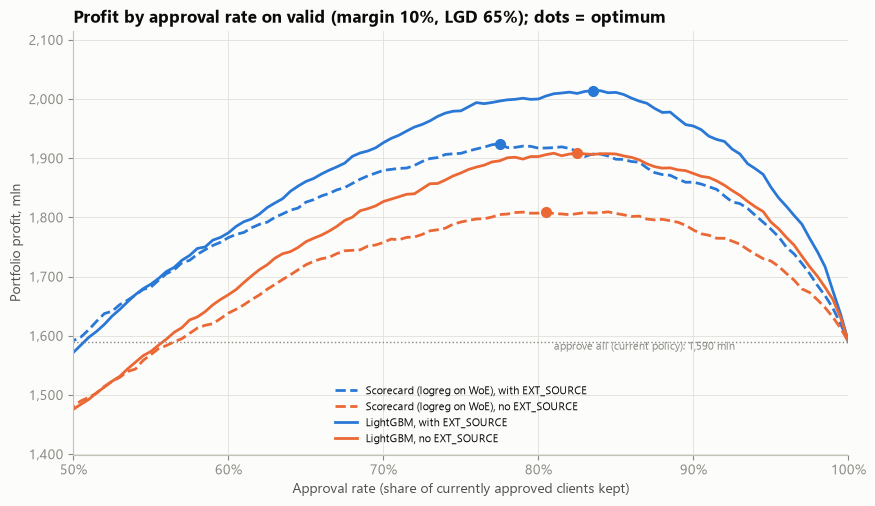

In [14]:
MLN = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}")
STYLE = {"scorecard": "--", "lightgbm": "-"}
COLOR = {"with_ext": SERIES[0], "no_ext": SERIES[1]}

fig, ax = plt.subplots(figsize=(10, 5.5))
for key, label in MODELS.items():
    model_type, version = key.split("_", 1)
    c = curves[key]
    ax.plot(c["approval_rate"], c["profit"], color=COLOR[version], linestyle=STYLE[model_type], label=label)
    best = optimal_cutoff(c)
    ax.plot(best["approval_rate"], best["profit"], "o", color=COLOR[version], markersize=7)
ax.axhline(baseline_profit, color=INK_MUTED, linestyle=":", linewidth=1)
ax.text(0.62, baseline_profit, f"approve all (current policy): {baseline_profit / 1e6:,.0f} mln",
        transform=ax.get_yaxis_transform(), va="top", fontsize=8, color=INK_MUTED)
ax.set_xlim(0.5, 1.0)
ax.set_ylim(baseline_profit * 0.88, economics["opt_profit"].max() * 1.05)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(MLN)
ax.set_xlabel("Approval rate (share of currently approved clients kept)")
ax.set_ylabel("Portfolio profit, mln")
ax.set_title(f"Profit by approval rate on valid (margin {MARGIN:.0%}, LGD {LGD:.0%}); dots = optimum")
ax.legend(loc="lower center", fontsize=8)

save_figure(fig, "04_profit_curve", FIGURES_DIR)
plt.show()

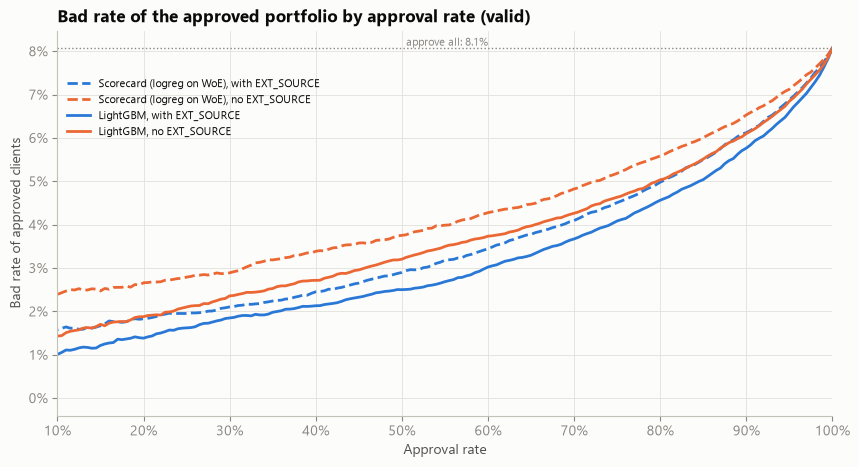

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for key, label in MODELS.items():
    model_type, version = key.split("_", 1)
    c = curves[key]
    ax.plot(c["approval_rate"], c["bad_rate"], color=COLOR[version], linestyle=STYLE[model_type], label=label)
ax.axhline(y.mean(), color=INK_MUTED, linestyle=":", linewidth=1)
ax.text(0.45, y.mean(), f"approve all: {y.mean():.1%}", transform=ax.get_yaxis_transform(),
        va="bottom", fontsize=8, color=INK_MUTED)
ax.set_xlim(0.1, 1.0)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Approval rate")
ax.set_ylabel("Bad rate of approved clients")
ax.set_title("Bad rate of the approved portfolio by approval rate (valid)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.9), fontsize=8)

save_figure(fig, "04_bad_rate_curve", FIGURES_DIR)
plt.show()

In [16]:
# Realized vs expected profit along the curve of the main model: close lines = PD can be trusted in money
c = curves["scorecard_with_ext"]
check = c.iloc[::20][["approval_rate", "profit", "expected_profit"]].assign(
    gap_pct=lambda t: (t["expected_profit"] - t["profit"]) / t["profit"].abs())
check.round(3)

,approval_rate,profit,expected_profit,gap_pct
0,0.005,2.291036e+07,2.657877e+07,0.160
20,0.105,4.337633e+08,4.569095e+08,0.053
40,0.205,7.894199e+08,8.170548e+08,0.035
60,0.305,1.107342e+09,1.128375e+09,0.019
80,0.405,1.384457e+09,1.402461e+09,0.013
100,0.505,1.598304e+09,1.634279e+09,0.023
120,0.605,1.771402e+09,1.822199e+09,0.029
140,0.705,1.881325e+09,1.956201e+09,0.040
160,0.805,1.917373e+09,2.021271e+09,0.054
180,0.905,1.856460e+09,1.985114e+09,0.069
